# 02 — Exploratory Data Analysis (EDA)

Analyse descriptive, analyse du target, variables numériques/catégorielles, corrélation, feature engineering et sauvegarde du dataset.

## Imports

In [1]:
import pandas as pd
import numpy as np

# import matplotlib.pyplot as plt
# import seaborn as sns

# from sklearn.preprocessing import StandardScaler

# from sklearn.impute import KNNImputer


In [38]:
df = pd.read_csv("../data/processed/dataset_clean.csv")

print(df.shape)
df.head()

(768, 9)


,Unnamed: 0,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,4,0,137.0,40.0,35.0,168.0,43.1,2.288,33


## Determine Numeric Columns and NULl values

In [39]:
features = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age"
]
df[features].isnull().sum()

Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
dtype: int64

## Visualize NAN values in Hitmap

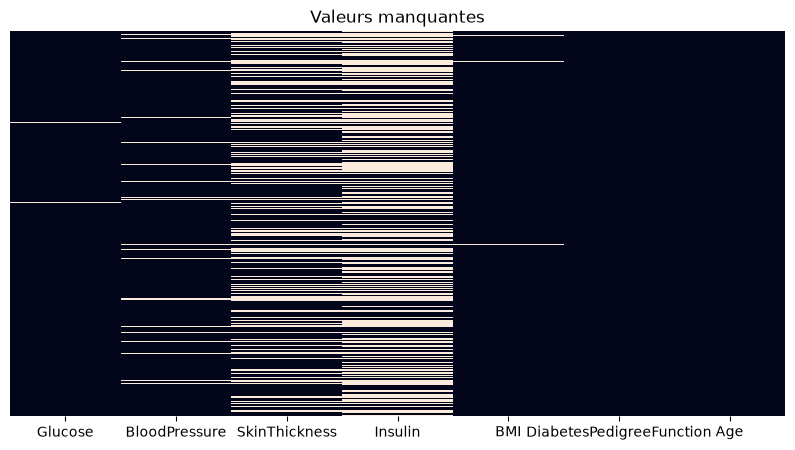

In [40]:
plt.figure(figsize=(10, 5))

sns.heatmap(
    df[features].isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Valeurs manquantes")
plt.show()

## Outliers with IQR


In [17]:
# 4. IQR
# ==========================================

Q1 = df[features].quantile(0.25)
Q3 = df[features].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[features] < lower_bound) |
    (df[features] > upper_bound)
)

print("\nOutliers par variable :")
print(outlier_mask.sum())


Outliers par variable :
Glucose                       0
BloodPressure                14
SkinThickness                87
Insulin                     346
BMI                           8
DiabetesPedigreeFunction     29
Age                           9
dtype: int64


## Visualiser les outliers — Boxplots

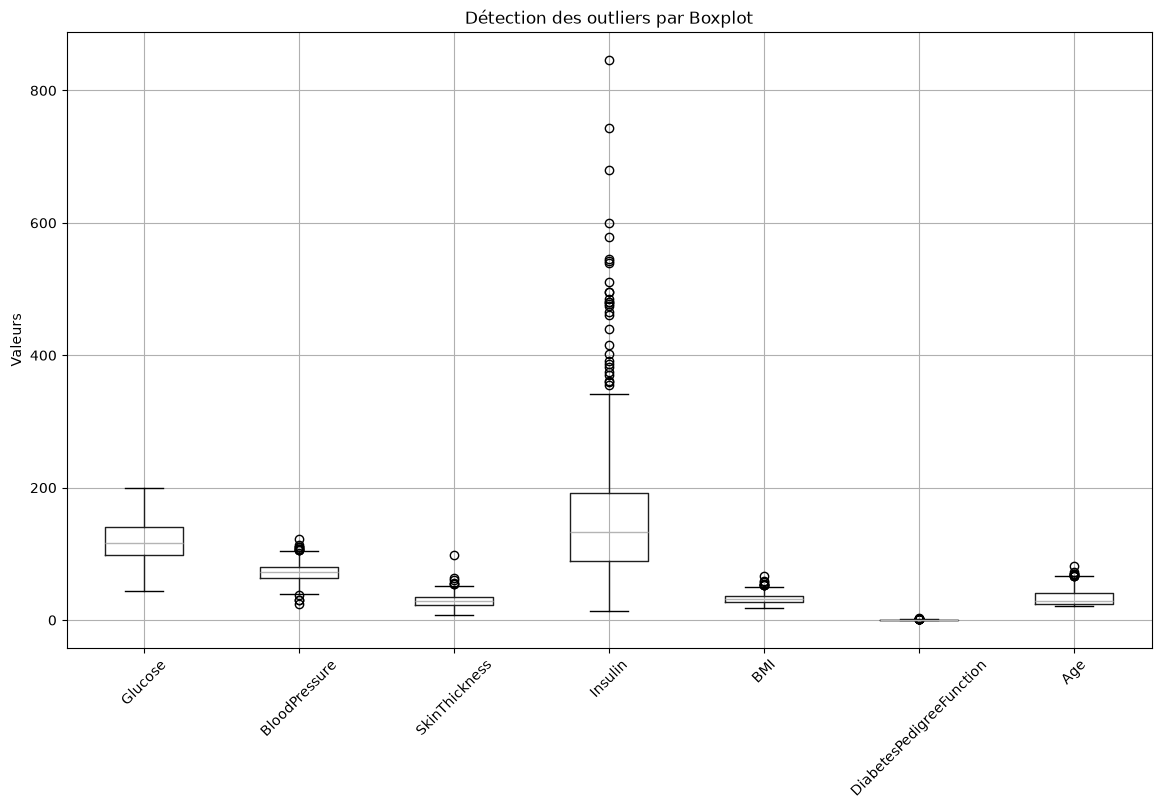

In [52]:
plt.figure(figsize=(14, 8))

df[features].boxplot()

plt.title("Détection des outliers par Boxplot")
plt.ylabel("Valeurs")
plt.xticks(rotation=45)

plt.show()

# 6. Matrice de corrélation


Corrélation :
                           Glucose  BloodPressure  SkinThickness   Insulin  \
Glucose                   1.000000       0.218937       0.192615  0.419451   
BloodPressure             0.218937       1.000000       0.191892  0.045363   
SkinThickness             0.192615       0.191892       1.000000  0.155610   
Insulin                   0.419451       0.045363       0.155610  1.000000   
BMI                       0.231049       0.281257       0.543205  0.180241   
DiabetesPedigreeFunction  0.137327      -0.002378       0.102188  0.126503   
Age                       0.266909       0.324915       0.126107  0.097101   

                               BMI  DiabetesPedigreeFunction       Age  
Glucose                   0.231049                  0.137327  0.266909  
BloodPressure             0.281257                 -0.002378  0.324915  
SkinThickness             0.543205                  0.102188  0.126107  
Insulin                   0.180241                  0.126503  0.0971

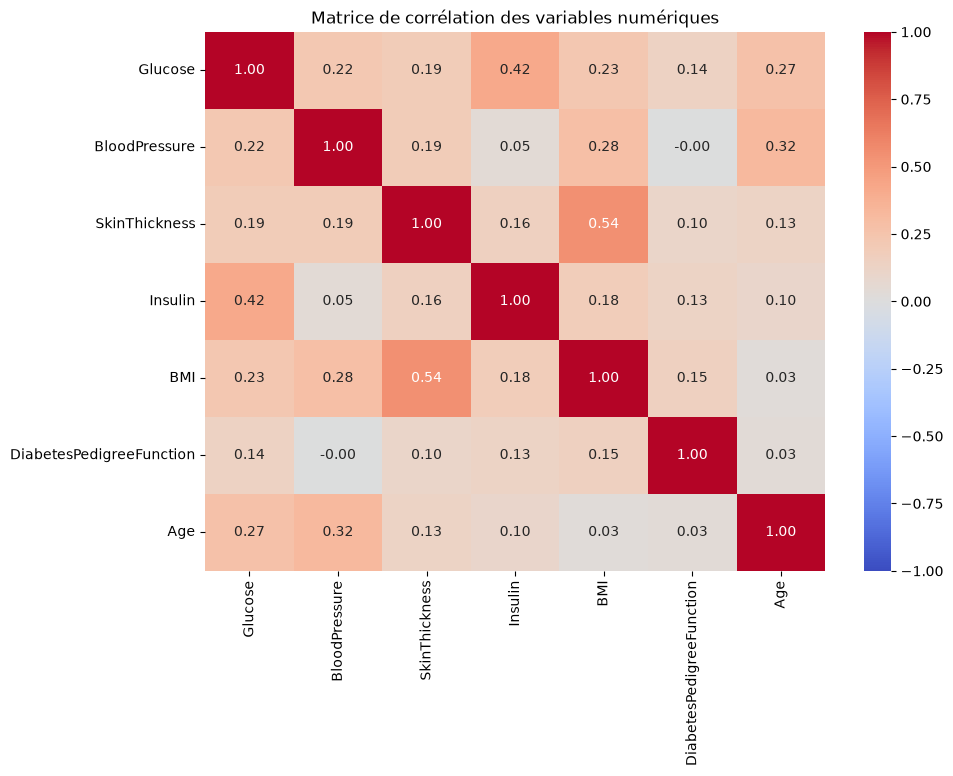

In [20]:
# ==========================================
# 6. Corrélation
# ==========================================

correlation = df[features].corr()

print("\nCorrélation :")
print(correlation)



correlation_matrix = df[features].corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Matrice de corrélation des variables numériques")
plt.show()


## le coefficient de variation

In [23]:
mean_values = df[features].mean()
std_values = df[features].std()

cv = std_values / mean_values

cv = cv.sort_values(
    ascending=False
)

print(cv)




DiabetesPedigreeFunction    0.702151
Insulin                     0.614075
Age                         0.353788
SkinThickness               0.302020
Glucose                     0.250199
BMI                         0.211836
BloodPressure               0.167111
dtype: float64


## les relations avec Pairplot

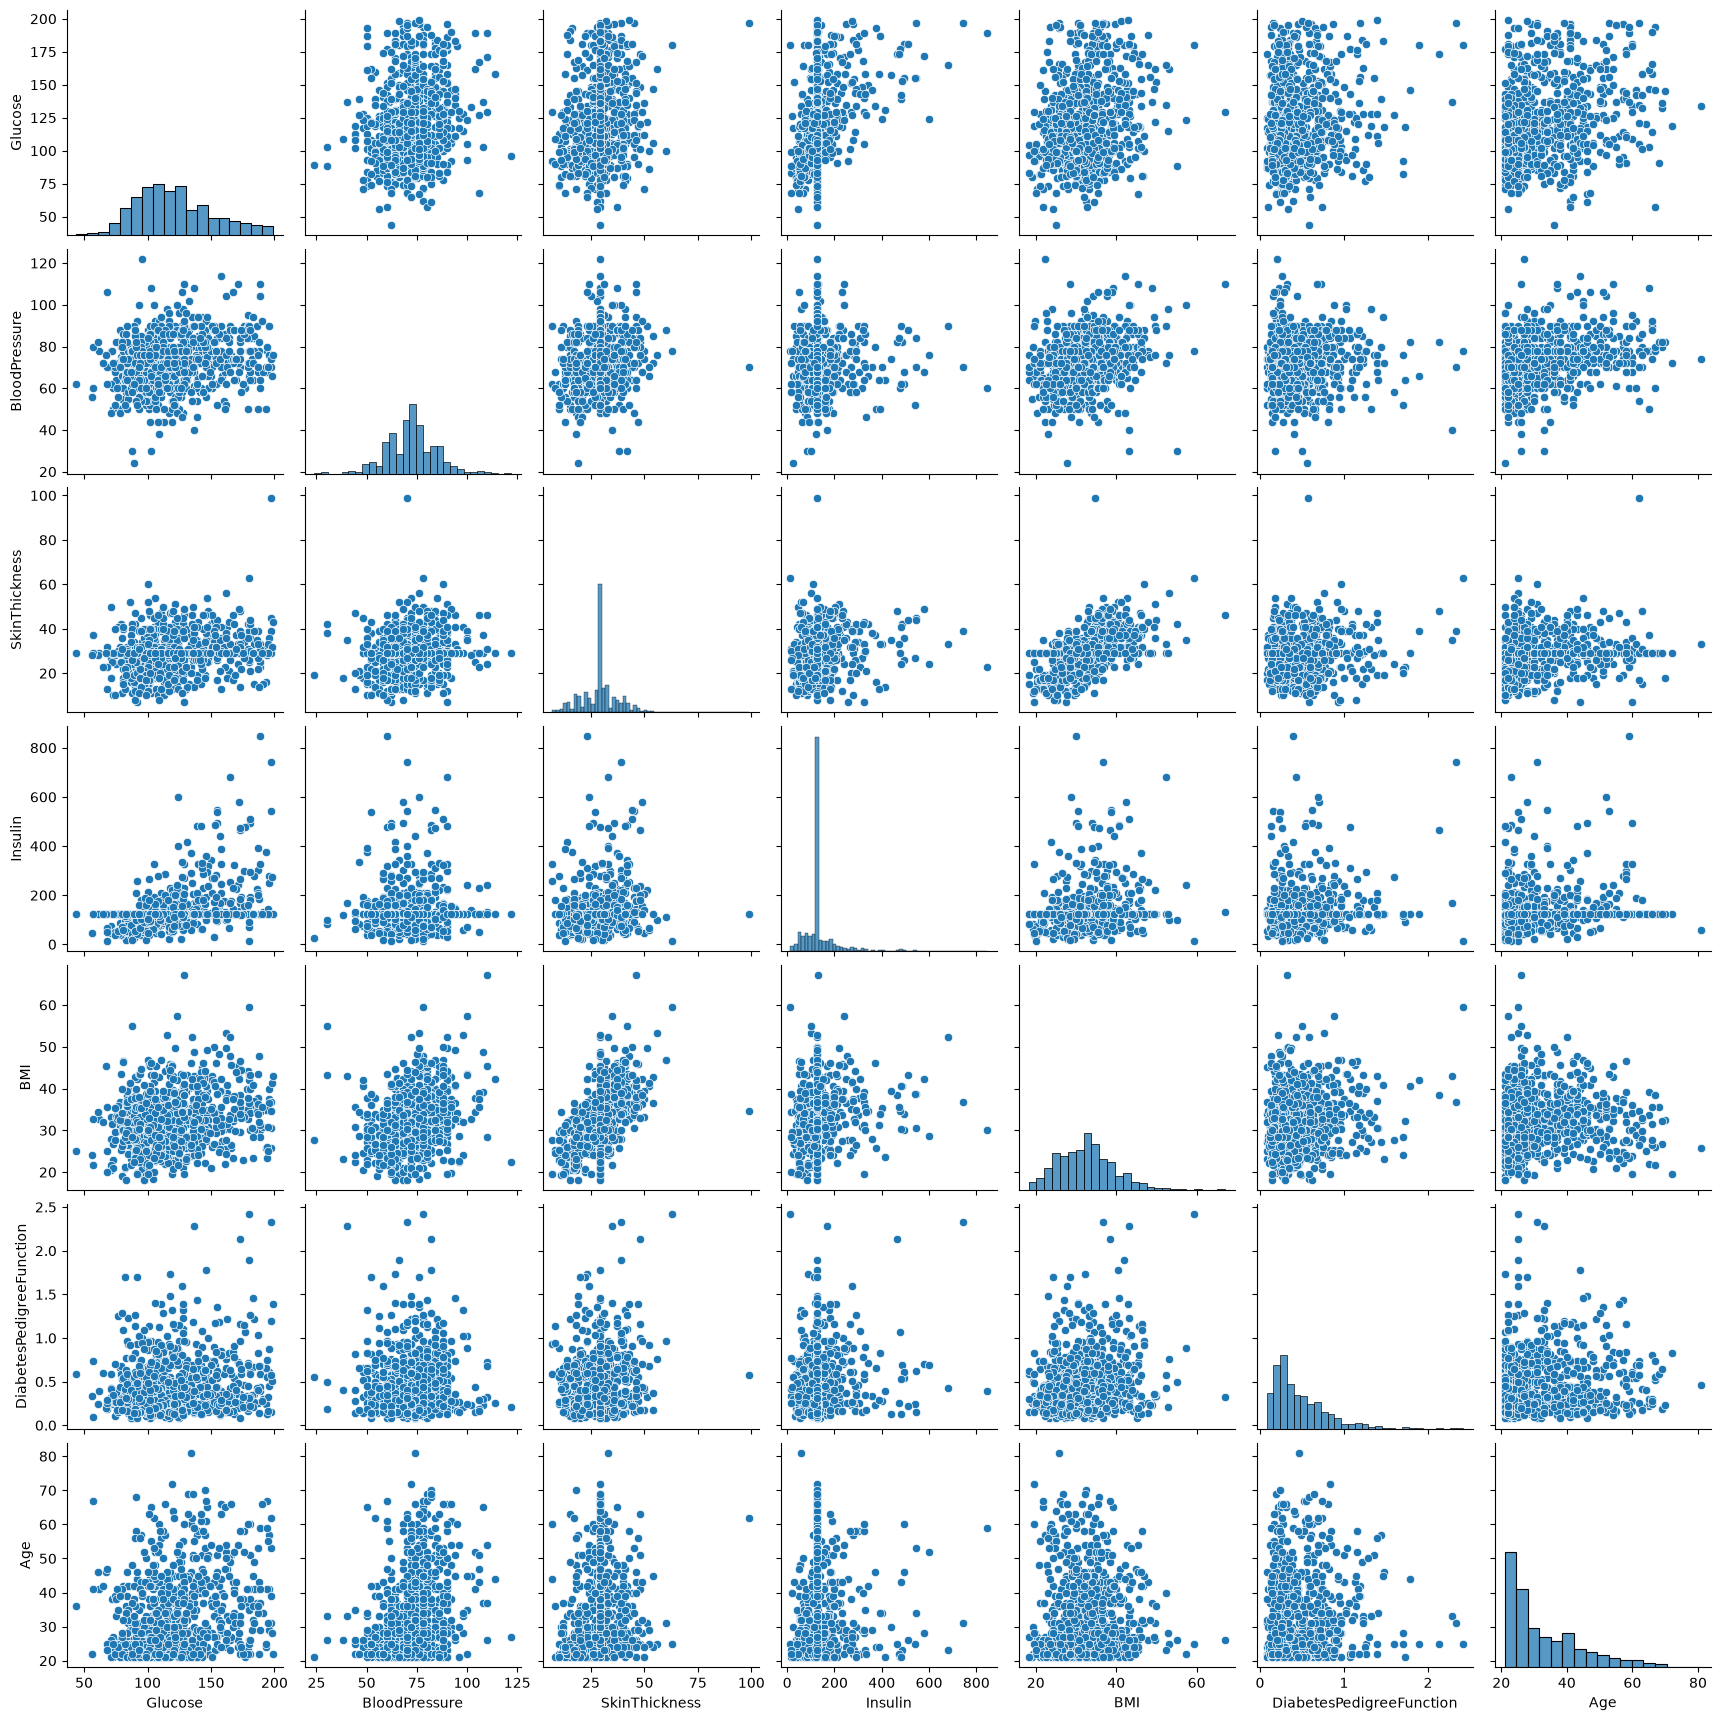

In [24]:
sns.pairplot(
    df[features]
)

plt.show()

## Standardisation des variables

In [45]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[features]
)

In [59]:
X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

print(X_scaled.head())

    Glucose  BloodPressure  SkinThickness   Insulin       BMI  \
0  0.862287      -0.032746       0.558557       NaN  0.165097   
1 -1.202229      -0.517645      -0.014657       NaN -0.846404   
2  2.009241      -0.679278            NaN       NaN -1.323254   
3 -1.071148      -0.517645      -0.587871 -0.518847 -0.629654   
4  0.501816      -2.618874       0.558557  0.104968  1.537847   

   DiabetesPedigreeFunction       Age  
0                  0.468492  1.425995  
1                 -0.365061 -0.190672  
2                  0.604397 -0.105584  
3                 -0.920763 -1.041549  
4                  5.484909 -0.020496  


In [47]:
print(X_scaled.mean())
print(X_scaled.std(ddof=0))



Glucose                     1.070936e-16
BloodPressure              -4.871047e-16
SkinThickness              -3.447643e-17
Insulin                     1.127130e-17
BMI                         3.660656e-16
DiabetesPedigreeFunction    2.451743e-16
Age                         1.931325e-16
dtype: float64
Glucose                     1.0
BloodPressure               1.0
SkinThickness               1.0
Insulin                     1.0
BMI                         1.0
DiabetesPedigreeFunction    1.0
Age                         1.0
dtype: float64


## KNN Imputation Replace Null Values

In [48]:
imputer = KNNImputer(
    n_neighbors=5
)

X_imputed_scaled = imputer.fit_transform(
    X_scaled
)

In [49]:
X_imputed = scaler.inverse_transform(
    X_imputed_scaled
)
df_imputed = pd.DataFrame(
    X_imputed,
    columns=features,
    index=df.index
)

In [50]:
df[features] = df_imputed

## StandardScaler final

In [60]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    df[features]
)

In [61]:
X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=features,
    index=df.index
)

## Save


In [63]:
df.to_csv(
    "../data/processed/cleaned_data.csv",
    index=False
)

X_scaled_df.to_csv(
    "../data/processed/scaled_features.csv",
    index=False
)